<small>📌 <b>먼저 내 노트로 저장하기</b></small><br><small>이 노트는 내 구글 드라이브의 『Colab Notebooks』 폴더(자동 사본으로 만들었으면 『배화 Colab 실습』 폴더)에 저장돼요.</small><br><small>사이트의 「▶ 내 Colab 노트 만들기」로 열었으면 사본·공유가 이미 돼 있어요 — 아래 ①~④ 는 건너뛰어도 돼요.</small><br><br><small>① 맨 위 <b>파일 → Drive에 사본 저장</b> (안 하면 쓴 게 사라져요)</small><br><img src="https://baehwa-ai-2026.web.app/aisocial/img/colab_step_copy.jpg" width="300"><br><br><small>② 사본이 열리면 오른쪽 위 <b>공유</b> 단추를 눌러요.</small><br><img src="https://baehwa-ai-2026.web.app/aisocial/img/colab_step_share.jpg" width="300"><br><br><small>③ 일반 액세스에서 <b>「링크가 있는 모든 사용자」</b>를 고른 다음 <b>링크 복사</b>.</small><br><img src="https://baehwa-ai-2026.web.app/aisocial/img/colab_step_anyone.jpg" width="300"><br><br><small>④ 사이트로 돌아와 <b>『📓 내 Colab 실습 노트』</b> 칸에 붙여넣고 <b>『보관』</b>을 눌러요 — <b>『✅ 보관됨』</b>이 뜨면 선생님께 간 거예요.</small><br><img src="https://baehwa-ai-2026.web.app/aisocial/img/colab_step_paste.jpg" width="300">

<small>☁ <b>저장 확인</b> — 맨 위 노트 이름 옆에 <b>체크된 구름</b>이 보이면 내 드라이브에 <b>실시간으로 저장</b>되고 있어요. (구름이 없고 「Drive로 복사」가 보이면 아직 내 노트가 아니에요 — 파일 → Drive에 사본 저장)</small><br>

![체크된 구름 = 저장 잘 되는 중](https://raw.githubusercontent.com/SoojiNoh/baehwa-colab/main/nb/img/colab_saved.png)

# 🎬 한국어 영화 리뷰 감정 분류 (심화) — 머신러닝

네이버 영화 리뷰(NSMC, 원저자 GitHub · 캐글 soohyun/naver-movie-review-dataset) · 캐글 Code 흐름(TF-IDF + 로지스틱 회귀)을 줄였어요. 한국어는 낱말을 나누기 어려워 「글자 2~3개 묶음」으로 셉니다.

- (심화) 노트예요: 빈칸 없이 끝까지 돌아가요. 한 칸씩 실행하며 숫자와 그래프를 읽고, 보고서 「1-1·1-2·1-3」에 써요.

In [1]:
# 0. 준비 — 그대로 실행해요
!pip -q install koreanize-matplotlib   # 한글 그래프 글꼴
import koreanize_matplotlib
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

## 1. 데이터 불러오기 — 원본 15만 개 중 2만 개

In [2]:
df = pd.read_csv('https://raw.githubusercontent.com/e9t/nsmc/master/ratings_train.txt', sep='\t').dropna()
df = df.sample(n=20000, random_state=0)
print(df.shape)
df.head()

(20000, 3)
              id                                  document  label
116100   9898962                         퇴보 된 한국영화들...씁쓸하다      1
57069    7967457                                     재밌는데?      1
93655    5151948  최민수가 더 건방지게 된 계기ㅋㅋㅋㅋㅋㅋㅋㅋㅋㅋㅋㅋㅋ 김정식한테 털리놈이      0
102593   2691285          정말 정말 잊을수 없는 재밌는 영화... 또 보고싶다...      1
146318  10024810                            볼만한 영화임 꼭 보셈ㅇㅇ      1


## 2. EDA — 모델 힌트가 되는 것만
긍정·부정이 반반이라 정확도로 봐도 괜찮아요. 리뷰는 대부분 짧아요.

label
0    0.503
1    0.497
Name: proportion, dtype: float64


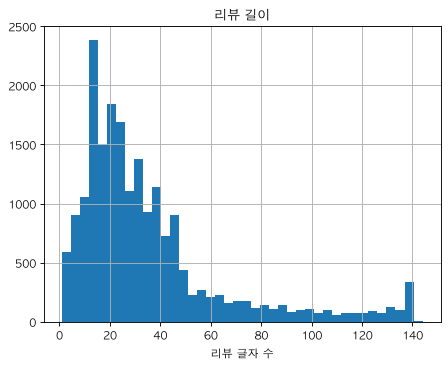

In [3]:
print(df['label'].value_counts(normalize=True).round(3))
df['길이'] = df['document'].str.len()
df['길이'].hist(bins=40); plt.xlabel('리뷰 글자 수'); plt.title('리뷰 길이'); plt.show()

## 3. 글 → 숫자 (글자 묶음 TF-IDF)

In [4]:
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
X_train, X_test, y_train, y_test = train_test_split(df['document'], df['label'], test_size=0.2, random_state=0)
vec = TfidfVectorizer(analyzer='char_wb', ngram_range=(2, 3), min_df=3, max_features=50000)
Xtr = vec.fit_transform(X_train); Xte = vec.transform(X_test)

## 4. 모델 학습 — 로지스틱 회귀

In [5]:
from sklearn.linear_model import LogisticRegression
model = LogisticRegression(max_iter=2000, C=2)
model.fit(Xtr, y_train)
pred = model.predict(Xte)

## 5. 성능평가

정확도 0.85 · F1 0.846


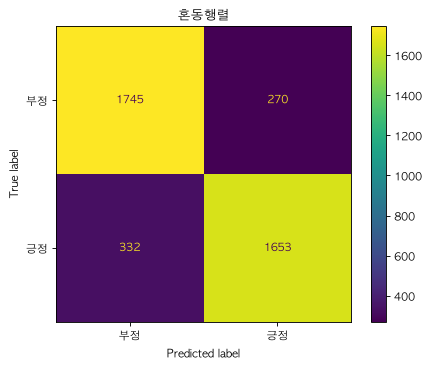

In [6]:
from sklearn.metrics import accuracy_score, f1_score, ConfusionMatrixDisplay
print('정확도', round(accuracy_score(y_test, pred), 3), '· F1', round(f1_score(y_test, pred), 3))
ConfusionMatrixDisplay.from_predictions(y_test, pred, display_labels=['부정', '긍정']); plt.title('혼동행렬'); plt.show()

## 6. 생각해 보기
- 「재미없지는 않은데」처럼 부정어가 섞인 리뷰는 맞혔을까요? → 「1-3 한계」